# Đồ thị 12 EF trung bình theo nhóm tuổi

**Võ Minh Huy — 2311110117**

Tổng hợp ejection_fraction theo bốn nhóm tuổi A1–A4 trên đủ 299 hồ sơ. Mỗi điểm là mean của một nhóm, kèm cỡ nhóm. Các điểm nối theo thứ tự nhóm tuổi, không phải chuỗi thời gian hoặc theo dõi cùng bệnh nhân qua các năm. Không cần nhãn DEATH_EVENT.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
for cot in ["age","MaNhomTuoi","ejection_fraction"]:
    du_lieu[cot] = pd.to_numeric(du_lieu[cot],errors="raise")
if len(du_lieu) != 299 or du_lieu[["age","MaNhomTuoi","ejection_fraction"]].isna().any().any():
    raise ValueError("Cần đủ 299 hồ sơ không thiếu tuổi, mã nhóm hoặc EF.")
assert du_lieu["age"].between(40,95).all()
assert du_lieu["ejection_fraction"].between(0,100).all()
ma_tu_tuoi = np.select([du_lieu["age"]<50,du_lieu["age"]<60,du_lieu["age"]<70],[1,2,3],default=4)
assert np.array_equal(ma_tu_tuoi,du_lieu["MaNhomTuoi"].to_numpy())
bang = du_lieu.groupby("MaNhomTuoi")["ejection_fraction"].agg(
    SoHoSo="size",SoEFHopLe="count",TongEF="sum",EFMean="mean",EFMedian="median").reindex([1,2,3,4])
assert bang["SoHoSo"].tolist() == [42,77,111,69]
assert bang["SoHoSo"].eq(bang["SoEFHopLe"]).all()
assert np.allclose(bang["EFMean"],bang["TongEF"]/bang["SoEFHopLe"])
assert np.isclose(np.average(bang["EFMean"],weights=bang["SoHoSo"]),du_lieu["ejection_fraction"].mean())
bang_tong_hop = bang.reset_index()
bang_tong_hop.insert(1,"KhoangTuoi",["Dưới 50","50 đến dưới 60","60 đến dưới 70","Từ 70 trở lên"])
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/12_duong_ef_nhom_tuoi"
thu_muc_kq.mkdir(parents=True,exist_ok=True)
bang_tong_hop.round(2)


,MaNhomTuoi,KhoangTuoi,SoHoSo,SoEFHopLe,TongEF,EFMean,EFMedian
0,1,Dưới 50,42,42,1583.0,37.69,35.0
1,2,50 đến dưới 60,77,77,2915.0,37.86,38.0
2,3,60 đến dưới 70,111,111,4225.0,38.06,38.0
3,4,Từ 70 trở lên,69,69,2664.0,38.61,38.0


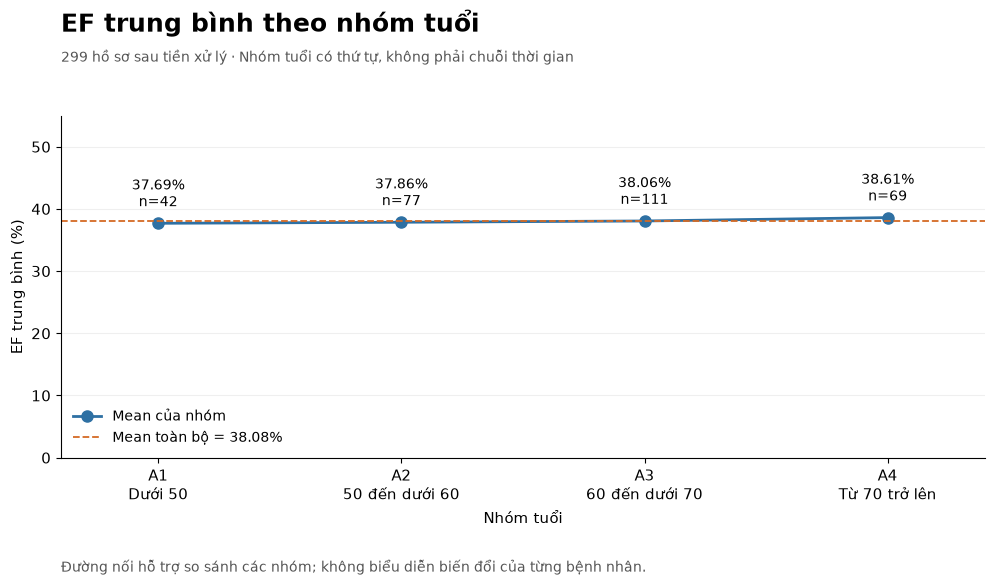

In [2]:
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
fig, ax = plt.subplots(figsize=(10.5,6))
fig.subplots_adjust(top=0.80,bottom=0.23,left=0.10,right=0.98)
fig.text(0.10,0.94,"EF trung bình theo nhóm tuổi",fontsize=18,weight="bold")
fig.text(0.10,0.89,"299 hồ sơ sau tiền xử lý · Nhóm tuổi có thứ tự, không phải chuỗi thời gian",color="#555555",fontsize=10)
x = np.arange(4)
y = bang["EFMean"].to_numpy()
duong, = ax.plot(x,y,color="#2E70A3",linewidth=2,marker="o",markersize=8,label="Mean của nhóm")
assert np.array_equal(duong.get_ydata(),y)
mean_chung = du_lieu["ejection_fraction"].mean()
ax.axhline(mean_chung,color="#D46A24",linestyle="--",linewidth=1.3,label=f"Mean toàn bộ = {mean_chung:.2f}%")
for i, r in enumerate(bang.to_dict("records")):
    ax.text(i,r["EFMean"]+2,f'{r["EFMean"]:.2f}%\nn={r["SoHoSo"]}',ha="center",va="bottom",fontsize=10)
ax.set_xticks(x,labels=["A1\nDưới 50","A2\n50 đến dưới 60","A3\n60 đến dưới 70","A4\nTừ 70 trở lên"])
ax.set(xlabel="Nhóm tuổi",ylabel="EF trung bình (%)",ylim=(0,55),xlim=(-0.4,3.4))
ax.set_yticks(np.arange(0,51,10))
ax.grid(axis="y",alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(frameon=False,loc="lower left",fontsize=10)
fig.text(0.10,0.04,"Đường nối hỗ trợ so sánh các nhóm; không biểu diễn biến đổi của từng bệnh nhân.",fontsize=10,color="#555555")
fig.savefig(thu_muc_kq / "12_duong_ef_nhom_tuoi.png",dpi=300,bbox_inches="tight",facecolor="white")
bang_tong_hop.to_csv(thu_muc_kq / "tong_hop_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

Đọc mean EF và cỡ mẫu ở từng nhóm; so sánh với đường mean chung khoảng 38,08%. Các điểm là giá trị tổng hợp nên không thể hiện phân tán trong nhóm. Không có khoảng tin cậy hoặc kiểm định trong đồ thị này; không kết luận khác biệt có ý nghĩa thống kê chỉ từ khoảng cách giữa các điểm.

Khi gộp mean các nhóm, phải dùng số hồ sơ làm trọng số, không lấy trung bình đơn giản của bốn mean. Tuổi và EF đã được xử lý, có thể chứa giá trị điền ở N02 và N07. Giữ đủ 299 hồ sơ, gồm hồ sơ chờ xác minh DEATH_EVENT; không thay đổi file after.
